[![preview notebook](https://img.shields.io/static/v1?label=render%20on&logo=github&color=87ce3e&message=GitHub)](https://github.com/open-atmos/PySDM/blob/main/examples/PySDM_examples/featured/Ware_et_al_2025/fig_1.ipynb)
[![launch on mybinder.org](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/open-atmos/PySDM.git/main?urlpath=lab/tree/examples/PySDM_examples/featured/Ware_et_al_2025/fig_1.ipynb)
[![launch on Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/open-atmos/PySDM/blob/main/examples/PySDM_examples/featured/Ware_et_al_2025/fig_1.ipynb)

# Fig. 1 in [Ware et al. 2025](https://doi.org/10.48550/arXiv.2509.05536)

In [1]:
import os, sys
os.environ['NUMBA_THREADING_LAYER'] = 'workqueue'  # PySDM & PyMPDATA don't work with TBB; OpenMP has extra dependencies on macOS
if 'google.colab' in sys.modules:
    !pip --quiet install open-atmos-jupyter-utils
    from open_atmos_jupyter_utils import pip_install_on_colab
    pip_install_on_colab('PySDM-examples', 'PySDM')

In [2]:
import numpy as np

from matplotlib import pyplot
from matplotlib.ticker import ScalarFormatter
from matplotlib.colors import LogNorm
from cmcrameri import cm
import seaborn as sns
from open_atmos_jupyter_utils import show_plot

from PySDM_examples.featured.Ware_et_al_2025.example import run, Settings, SpectrumPlotter
from PySDM.initialisation.sampling.spectral_sampling import ConstantMultiplicity
from PySDM.backends import CPU

dt=20, n_sd=12, exec_time=2.67, it=0
dt=20, n_sd=12, exec_time=0.02, it=1
dt=20, n_sd=12, exec_time=0.02, it=2
dt=20, n_sd=12, exec_time=0.02, it=3
dt=20, n_sd=12, exec_time=0.03, it=4
dt=20, n_sd=12, exec_time=0.03, it=5
dt=20, n_sd=12, exec_time=0.02, it=6
dt=20, n_sd=12, exec_time=0.02, it=7
dt=20, n_sd=12, exec_time=0.03, it=8
dt=20, n_sd=12, exec_time=0.02, it=9
dt=20, n_sd=12, exec_time=0.02, it=10
dt=20, n_sd=12, exec_time=0.03, it=11
dt=20, n_sd=12, exec_time=0.03, it=12
dt=20, n_sd=12, exec_time=0.05, it=13
dt=20, n_sd=12, exec_time=0.03, it=14
dt=20, n_sd=12, exec_time=0.03, it=15
dt=20, n_sd=12, exec_time=0.03, it=16
dt=20, n_sd=12, exec_time=0.03, it=17
dt=20, n_sd=12, exec_time=0.03, it=18
dt=20, n_sd=12, exec_time=0.03, it=19
dt=20, n_sd=12, exec_time=0.03, it=20
dt=20, n_sd=12, exec_time=0.02, it=21
dt=20, n_sd=12, exec_time=0.02, it=22
dt=20, n_sd=12, exec_time=0.02, it=23
dt=20, n_sd=12, exec_time=0.02, it=24
dt=20, n_sd=12, exec_time=0.02, it=25
dt=20, n_sd=12, exec_t

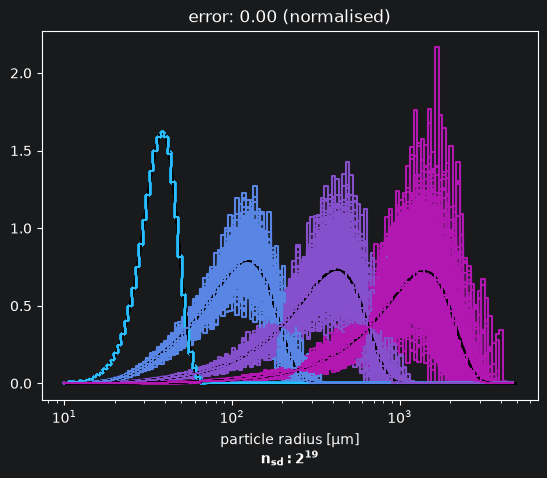

In [3]:
backend = CPU()
n_sds = 12, 13, 14, 15, 16, 17, 18, 19
dts = 20, 10, 5, 2, 1

regular = {}
meanoutputs = {}
n_iters = 2 if 'CI' in os.environ else 50
base_time = None
base_error = None

error_heatmap = [[0 for _ in range(len(n_sds))] for _ in range(len(dts))]
error_std_hm = [[0 for _ in range(len(n_sds))] for _ in range(len(dts))]
deficit_heatmap = [[0 for _ in range(len(n_sds))] for _ in range(len(dts))]
mean_time_heatmap = [[0 for _ in range(len(n_sds))] for _ in range(len(dts))]
sanity_heatmap = [[0 for _ in range(len(n_sds))] for _ in range(len(dts))]
plotter = SpectrumPlotter(Settings(), legend=False)
plotter.smooth = False

for i, dt in enumerate(dts):
    for j, n_sd in enumerate(n_sds):
        sanity_heatmap[i][j] = "dt="+str(dt)+", n_sd="+str(n_sd)
        outputs = []
        deficits = []
        errors = []

        for it in range(n_iters):
            settings = Settings()
            backend.formulae.seed = it

            settings.n_sd = 2**n_sd
            settings.dt = dt 
            settings.adaptive = False 
            settings.sampling = ConstantMultiplicity(settings.spectrum)

            states, exec_time, deficit = run(settings,backend)
            deficit *= settings.dv
            print(f"{dt=}, {n_sd=}, {exec_time=:.2f}, {it=}")

            outputs.append(states)
            deficits.append(deficit)

            for step, vals in states.items():
                error = plotter.plot(vals, step * settings.dt)
            errors.append(error*1e-3) #grams to kg

        mean_output = {}

        for key in outputs[0].keys():
            mean_output[key] = sum((output[key] for output in outputs)) / len(
                outputs
            )

        mean_deficit = sum(deficits) / len(deficits)
        last_step_error = sum(errors) / len(errors)
        error_std = np.std(errors)

        plotter.ylabel = (
            r"$\bf{dt: "
            + str(settings.dt)
            + ("+ adaptivity" if settings.adaptive else "")
            + "}$\ndm/dlnr [g/m^3/(unit dr/r)]"
            if j == 0
            else None
        )
        plotter.xlabel = (
            "particle radius [µm]\n" + r"$\bf{n_{sd}: 2^{" + str(n_sd) + "}}$"
            if i == len(dts) - 1
            else None
        )
        plotter.title = (
            f"error: {last_step_error:.2f} (normalised)"
        )
        error_heatmap[i][j] = last_step_error
        error_std_hm[i][j] = error_std
        deficit_heatmap[i][j] = mean_deficit
        plotter.finished = False
        plotter.finish()
        meanoutputs[(n_sd,dt)] = mean_output
regular["Error"] = error_heatmap
regular["Error_std"] = error_std_hm
regular["Deficit"] = deficit_heatmap
regular["MeanTime"] = mean_time_heatmap

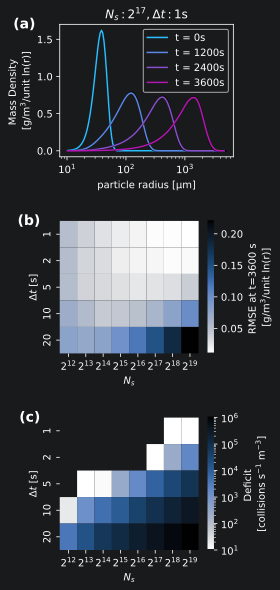

In [4]:
formatter = ScalarFormatter(useMathText=True)

error_matrix = np.array(regular["Error"])
error_matrix *= 1e3  # Convert to g/m^3
error_matrix_flipped = np.flipud(error_matrix)

deficit_matrix = np.array(regular["Deficit"])
deficit_matrix_flipped = np.flipud(deficit_matrix)
deficit_matrix_flipped = deficit_matrix_flipped[:,:,0]
deficit_matrix_flipped[deficit_matrix_flipped == 0] = np.nan

fig, axes = pyplot.subplots(3, 1, figsize=(4, 8.3), tight_layout=True)

plotter = SpectrumPlotter(Settings(), legend=False)
plotter.smooth = True
plotter.ax = axes[0]

for step, vals in meanoutputs[(choice_ns := 17, choice_dt := 1)].items():
    error = plotter.plot(vals, step * 1)

axes[0].set_title(fr"$N_{{s}}: 2^{{{choice_ns}}},\Delta t:{choice_dt}$s")
axes[0].set_xscale("log")
axes[0].set_ylabel("Mass Density \n[g/m$^3$/unit ln(r)]")
axes[0].set_xlabel("particle radius [µm]\n")
axes[0].legend()

X, Y = np.meshgrid(np.arange(len(n_sds)), np.arange(len(dts)))

sns.heatmap(error_matrix_flipped,
    ax=axes[1],cmap=cm.oslo_r,cbar=True,
    cbar_kws={"label": "RMSE at t=3600 s \n[g/m$^3$/unit ln(r)]",},
)
axes[1].set_yticks(np.arange(len(dts)))
axes[1].set_yticklabels(dts)

axes[1].set_xlabel("$N_s$")
axes[1].set_ylabel(r"$\Delta t$ [s]")

sns.heatmap(deficit_matrix_flipped,
    ax=axes[2],cmap=cm.oslo_r,cbar=True,
    norm=LogNorm(vmin=10,vmax=1e6),
    cbar_kws={"label": "Deficit \n[collisions s$^{-1}$ m$^{-3}$]"},
)
cbar = axes[2].collections[0].colorbar

for ax in axes[[1,2]]:
    ax.set_xticks(np.arange(len(n_sds)) + 0.5)
    ax.set_yticks(np.arange(len(dts)) + 0.5)
    ax.set_xticklabels([f"$2^{{{n}}}$" for n in n_sds])
    ax.set_yticklabels(dts[::-1])

axes[2].set_xlabel("$N_s$")
axes[2].set_ylabel(r"$\Delta t$ [s]")

for i, letter in enumerate(["a", "b", "c"]):
    axes[i].text(
        -0.14, 1.05, f"({letter})", transform=axes[i].transAxes,
        fontsize=14, fontweight="bold", va="top", ha="right"
    )

show_plot("fig_1")